# M5 Demand Forecasting → Inventory Decisions
## Notebook 03 — Forecasting (baselines, LightGBM, P50/P90)

**Goal:** forecast daily unit sales for every Texas FOODS product-store **28 days ahead**, measure how uncertain those forecasts are, and prove the model beats simple baselines. The forecasts feed the inventory simulation in Notebook 04.

**Input:** `data/processed/m5_tx_foods_long_flagged.parquet` (Notebooks 01–02) · **Output:** `data/processed/forecasts_backtest.parquet`

**Runtime:** ~10 minutes on Colab (9 LightGBM models).

### How it works (plain English)

1. **Forecast origin.** A store plans on a Monday using only what it knows *that Monday*. So every forecast has an **origin** (the Monday it's made) and covers the next 28 days. History features — "average sales over the last 7 / 28 / 56 / 112 days", "the last 4 same-weekdays" — are measured **as of the origin**, never later. That rules out leakage by construction.
2. **One global model.** Instead of 4,311 separate models, one LightGBM model learns from all products at once. Product-level differences come in through the history features (a fast seller has a high 28-day average).
3. **Three models, three jobs.**
   - **Mean** (Tweedie loss, built for counts with many zeros): *expected* demand, used for ordering.
   - **P50** (median) and **P90** (quantile loss): the middle and the "busy-day" level. P90 = "90% of days sell this much or less".
4. **Backtest, never shuffle.** We pretend to stand on three past Mondays (Feb 29, Mar 28, Apr 25, 2016), train on everything before, and forecast the next 28 days. That gives **12 weeks of honest out-of-sample forecasts**.
5. **Fair scoring.** Days flagged *likely unavailable* (Notebook 02) are excluded from training targets and from scoring — they aren't demand. Christmas is excluded from training.

**Baselines the model must beat** (all use only information available at the origin):

| Baseline | Forecast for a day |
|---|---|
| Seasonal naive | Sales on the same day 4 weeks earlier |
| Same-weekday average | Average of the 4 most recent same weekdays before the origin |
| 28-day moving average | Average daily sales over the 28 days before the origin |

## Setup

In [1]:
import os, sys, gc, json, time, warnings
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/m5-inventory'
else:
    PROJECT_DIR = os.path.abspath('..')          # running from the repo's notebooks/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

PROCESSED_DIR = os.path.join(PROJECT_DIR, 'data', 'processed')
FIG_DIR       = os.path.join(PROJECT_DIR, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Same chart style as Notebook 02
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 2, 'legend.frameon': False,
})
BLUE, ORANGE, GRAY, INK = '#2a78d6', '#eb6834', '#b5b4ad', '#52514e'

def save_fig(fig, name):
    path = os.path.join(FIG_DIR, f'{name}.png')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print('Saved:', os.path.relpath(path, PROJECT_DIR))

import lightgbm as lgb
print('LightGBM', lgb.__version__)

df = pd.read_parquet(os.path.join(PROCESSED_DIR, 'm5_tx_foods_long_flagged.parquet'))
df = df.sort_values(['store_id', 'item_id', 'date']).reset_index(drop=True)
print(f"{len(df):,} rows | {df[['item_id','store_id']].drop_duplicates().shape[0]:,} series | "
      f"{df['date'].min().date()} → {df['date'].max().date()} | flagged unavailable: {df['unavailable'].mean():.1%}")

LightGBM 4.7.0


6,773,457 rows | 4,311 series | 2011-01-29 → 2016-05-22 | flagged unavailable: 15.7%


## Step 1 — Build origin-based features

Every row gets a **horizon** (0–27 days after its origin) and history features measured on its origin day. Origins fall every 28 days, aligned so the last one is Monday 2016-04-25; that way training rows look exactly like the forecasts we'll make.

Because each series is a continuous daily block (Notebook 01 sorted it and removed pre-launch rows), "the value on the origin day" is just *this row's position minus its horizon* — so everything is computed with fast array arithmetic instead of slow loops.

| Feature group | Features |
|---|---|
| History as of origin | mean of last 7 / 28 / 56 / 112 days, 28-day std, share of zero days (28d), mean of last 4 same weekdays, last same weekday |
| Calendar (known ahead) | day of week, day of month, month, SNAP day, event name & type |
| Price (known ahead) | price, price vs. price on the day before the origin |
| Product context | department, store, days since launch, horizon |

In [2]:
H = 28
LAST_ORIGIN = pd.Timestamp('2016-04-25')

pos = df.groupby(['item_id', 'store_id'], observed=True).cumcount().to_numpy()   # day number within series
h   = np.mod((df['date'] - LAST_ORIGIN).dt.days.to_numpy(), H)                # horizon: days since origin
idx = np.arange(len(df))
s   = df['sales'].to_numpy(dtype='float32')

# Running totals make "mean of the w days before each row" a single subtraction
csum  = np.concatenate([[0.0], np.cumsum(s, dtype='float64')])
csum2 = np.concatenate([[0.0], np.cumsum(s.astype('float64') ** 2)])
czero = np.concatenate([[0.0], np.cumsum(s == 0, dtype='float64')])

def past_mean(c, w):
    """Mean of the w days BEFORE each row (same series only)."""
    out = (c[idx] - c[np.maximum(idx - w, 0)]) / w
    out[pos < w] = np.nan
    return out

def at_origin(x):
    """Take each row's value from its origin day (row - horizon)."""
    out = x[np.maximum(idx - h, 0)].astype('float32')
    out[pos - h < 0] = np.nan
    return out

def lag(k):
    out = s[np.maximum(idx - k, 0)].copy()
    out[pos < k] = np.nan
    return out

feats = {}
for w in [7, 28, 56, 112]:
    feats[f'o_mean_{w}'] = at_origin(past_mean(csum, w))
m28, m2 = past_mean(csum, 28), past_mean(csum2, 28)
feats['o_std_28']  = at_origin(np.sqrt(np.maximum(m2 - m28 ** 2, 0)))
feats['o_zero_28'] = at_origin(past_mean(czero, 28))

# The 4 most recent same-weekday days before the origin: horizon 0-6 -> lags 7..28, 7-13 -> 14..35, ...
k0 = h // 7 + 1
lags = {k: lag(k) for k in range(7, 56, 7)}
dow4 = np.full(len(df), np.nan, dtype='float32'); last_same = dow4.copy()
for kk in range(1, 5):
    m = k0 == kk
    dow4[m] = np.mean([lags[7 * (kk + j)][m] for j in range(4)], axis=0)
    last_same[m] = lags[7 * kk][m]
feats['o_dow_mean_4w'], feats['o_last_same_dow'] = dow4, last_same

price = df['sell_price'].to_numpy()
feats['price_vs_origin'] = (price / at_origin(np.r_[np.nan, price[:-1]])).astype('float32')
feats['horizon'] = h.astype('int8')
feats['days_since_launch'] = pos.astype('int16')
feats['snaive_28'] = lag(28).astype('float32')                     # baseline only, not a model feature

df = pd.concat([df, pd.DataFrame(feats)], axis=1)
df['dow'] = df['date'].dt.dayofweek.astype('int8')
df['dom'] = df['date'].dt.day.astype('int8')
df['month'] = df['date'].dt.month.astype('int8')
df['is_christmas'] = (df['date'].dt.month == 12) & (df['date'].dt.day == 25)
del feats, lags, csum, csum2, czero; _ = gc.collect()

FEATURES = ['dept_id', 'store_id', 'sell_price', 'price_vs_origin', 'snap', 'event_name_1', 'event_type_1',
            'dow', 'dom', 'month', 'horizon', 'days_since_launch',
            'o_mean_7', 'o_mean_28', 'o_mean_56', 'o_mean_112', 'o_std_28', 'o_zero_28',
            'o_dow_mean_4w', 'o_last_same_dow']
print(f"{len(FEATURES)} features | memory {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")

# Leakage check: on an origin Monday the 28-day feature must equal the true mean of the 28 days before it
row = df[(df['date'] == LAST_ORIGIN) & (df['item_id'] == 'FOODS_3_090') & (df['store_id'] == 'TX_2')].index[0]
assert np.isclose(df.loc[row, 'o_mean_28'], df.loc[row - 28:row - 1, 'sales'].mean())
assert df.loc[row, 'horizon'] == 0
print('✅ Features use only data before the origin')

20 features | memory 508 MB
✅ Features use only data before the origin


## Step 2 — Backtest: 3 origins × 3 models

For each origin **T**: train on 2014-06-01 → T−29, use the 28 days before T for early stopping (each model stops on its *own* loss), then forecast T → T+27.

| Fold | Train until | Early-stopping window | Forecast window |
|---|---|---|---|
| 1 | 2016-01-31 | Feb 1 – Feb 28 | **Feb 29 – Mar 27** |
| 2 | 2016-02-28 | Feb 29 – Mar 27 | **Mar 28 – Apr 24** |
| 3 | 2016-03-27 | Mar 28 – Apr 24 | **Apr 25 – May 22** |

In [3]:
ORIGINS = pd.to_datetime(['2016-02-29', '2016-03-28', '2016-04-25'])
TRAIN_START = pd.Timestamp('2014-06-01')
train_ok = ~df['unavailable'] & ~df['is_christmas']          # targets we trust

BASE_PARAMS = dict(learning_rate=0.05, num_leaves=63, min_data_in_leaf=200, max_bin=127,
                   feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
                   seed=42, verbose=-1)
MODELS = {
    'mean': dict(objective='tweedie', tweedie_variance_power=1.1, metric='tweedie'),
    'p50':  dict(objective='quantile', alpha=0.5, metric='quantile'),
    'p90':  dict(objective='quantile', alpha=0.9, metric='quantile'),
}
KEEP = ['item_id', 'store_id', 'dept_id', 'date', 'sales', 'unavailable', 'sell_price', 'horizon',
        'snaive_28', 'o_dow_mean_4w', 'o_mean_28', 'o_std_28']

results, importance = [], None
for fold, T in enumerate(ORIGINS, start=1):
    trn = (df['date'] >= TRAIN_START) & (df['date'] < T - pd.Timedelta(days=H)) & train_ok
    val = (df['date'] >= T - pd.Timedelta(days=H)) & (df['date'] < T) & train_ok
    tst = (df['date'] >= T) & (df['date'] < T + pd.Timedelta(days=H))
    dtrain = lgb.Dataset(df.loc[trn, FEATURES], df.loc[trn, 'sales'], free_raw_data=False)
    dvalid = lgb.Dataset(df.loc[val, FEATURES], df.loc[val, 'sales'], reference=dtrain)

    out = df.loc[tst, KEEP].copy()
    out['fold'] = fold
    for name, obj in MODELS.items():
        t0 = time.time()
        model = lgb.train({**BASE_PARAMS, **obj}, dtrain, num_boost_round=1500, valid_sets=[dvalid],
                          callbacks=[lgb.early_stopping(50, verbose=False)])
        out[name] = model.predict(df.loc[tst, FEATURES], num_iteration=model.best_iteration)
        print(f'fold {fold} | {name:4s} | {trn.sum():,} train rows | {model.best_iteration:4d} trees | {time.time() - t0:.0f}s')
        if name == 'mean' and fold == len(ORIGINS):
            importance = pd.Series(model.feature_importance('gain'), index=FEATURES)
    results.append(out)

fc = pd.concat(results, ignore_index=True)
# Forecasts can't be negative, and P90 can't sit below P50
fc['mean'] = fc['mean'].clip(lower=0)
fc['p50']  = fc['p50'].clip(lower=0)
fc['p90']  = np.maximum(fc['p90'], fc['p50'])
print(f"\n{len(fc):,} forecast rows ({fc['date'].min().date()} → {fc['date'].max().date()})")

fold 1 | mean | 2,144,794 train rows |  411 trees | 51s


fold 1 | p50  | 2,144,794 train rows |  260 trees | 44s


fold 1 | p90  | 2,144,794 train rows |  216 trees | 33s


fold 2 | mean | 2,249,873 train rows |  328 trees | 46s


fold 2 | p50  | 2,249,873 train rows |  217 trees | 40s


fold 2 | p90  | 2,249,873 train rows |  139 trees | 26s


fold 3 | mean | 2,358,922 train rows |  107 trees | 24s


fold 3 | p50  | 2,358,922 train rows |  125 trees | 35s


fold 3 | p90  | 2,358,922 train rows |  758 trees | 92s

362,124 forecast rows (2016-02-29 → 2016-05-22)


## Step 3 — Accuracy vs. baselines

Scored on the 12 test weeks, excluding *likely unavailable* days.

Two metrics, each matched to the forecast it suits: **RMSE** is minimised by the *mean*, **MAE** by the *median*. With intermittent demand (many zeros) the median is often 0, so a mean forecast always looks worse on MAE and a median forecast worse on RMSE. We therefore judge the **mean model on RMSE** and the **P50 model on MAE**. (MAPE is unusable: it divides by zero on zero-sales days.)

In [4]:
# Naive quantiles for comparison: empirical P50/P90 of the 28 days before each origin
hist = []
for fold, T in enumerate(ORIGINS, start=1):
    w = df[(df['date'] >= T - pd.Timedelta(days=28)) & (df['date'] < T)]
    q = w.groupby(['item_id', 'store_id'], observed=True)['sales'].quantile([0.5, 0.9]).unstack()
    q.columns = ['naive_p50', 'naive_p90']
    hist.append(q.reset_index().assign(fold=fold))
fc = fc.merge(pd.concat(hist), on=['item_id', 'store_id', 'fold'], how='left')

ev = fc[~fc['unavailable']]
def mae(col):  return (ev['sales'] - ev[col]).abs().mean()
def rmse(col): return np.sqrt(((ev['sales'] - ev[col]) ** 2).mean())
def bias(col): return (ev[col] - ev['sales']).mean() / ev['sales'].mean()

names = {'snaive_28': 'Seasonal naive (same day 4 wks ago)', 'o_dow_mean_4w': 'Same-weekday avg (last 4)',
         'o_mean_28': '28-day moving average', 'mean': 'LightGBM mean', 'p50': 'LightGBM P50 (median)'}
scores = pd.DataFrame({'MAE': {n: mae(c) for c, n in names.items()},
                       'RMSE': {n: rmse(c) for c, n in names.items()},
                       'Bias vs actual': {n: bias(c) for c, n in names.items()}})
print(f"Scored rows: {len(ev):,}  |  average daily sales: {ev['sales'].mean():.2f} units\n")
print(scores.round(3).to_string(formatters={'Bias vs actual': '{:+.1%}'.format}))

best_base_rmse = scores.loc[[names['snaive_28'], names['o_dow_mean_4w'], names['o_mean_28']], 'RMSE']
best_base_mae  = scores.loc[[names['snaive_28'], names['o_dow_mean_4w'], names['o_mean_28']], 'MAE']
print(f"\nLightGBM mean RMSE vs seasonal naive: {scores.loc['LightGBM mean','RMSE'] / best_base_rmse.iloc[0] - 1:+.1%} | "
      f"vs best baseline ({best_base_rmse.idxmin()}): {scores.loc['LightGBM mean','RMSE'] / best_base_rmse.min() - 1:+.1%}")
print(f"LightGBM P50 MAE  vs seasonal naive: {scores.loc['LightGBM P50 (median)','MAE'] / best_base_mae.iloc[0] - 1:+.1%} | "
      f"vs best baseline ({best_base_mae.idxmin()}): {scores.loc['LightGBM P50 (median)','MAE'] / best_base_mae.min() - 1:+.1%}")

by_fold = ev.groupby('fold').apply(lambda g: pd.Series({
    'MA28 RMSE': np.sqrt(((g['sales'] - g['o_mean_28']) ** 2).mean()),
    'LGBM mean RMSE': np.sqrt(((g['sales'] - g['mean']) ** 2).mean()),
    'MA28 MAE': (g['sales'] - g['o_mean_28']).abs().mean(),
    'LGBM P50 MAE': (g['sales'] - g['p50']).abs().mean()}))
print('\nBy fold:\n' + by_fold.round(3).to_string())

Scored rows: 339,725  |  average daily sales: 1.82 units

                                       MAE   RMSE Bias vs actual
Seasonal naive (same day 4 wks ago)  1.482  3.077          -3.6%
Same-weekday avg (last 4)            1.259  2.488          -3.5%
28-day moving average                1.218  2.458          -3.5%
LightGBM mean                        1.226  2.343          +5.5%
LightGBM P50 (median)                1.110  2.350         -22.0%

LightGBM mean RMSE vs seasonal naive: -23.9% | vs best baseline (28-day moving average): -4.7%
LightGBM P50 MAE  vs seasonal naive: -25.1% | vs best baseline (28-day moving average): -8.8%

By fold:
      MA28 RMSE  LGBM mean RMSE  MA28 MAE  LGBM P50 MAE
fold                                                   
1         2.491           2.358     1.243         1.132
2         2.389           2.361     1.200         1.077
3         2.492           2.311     1.211         1.121


Saved: reports/figures/03_01_accuracy_vs_baselines.png


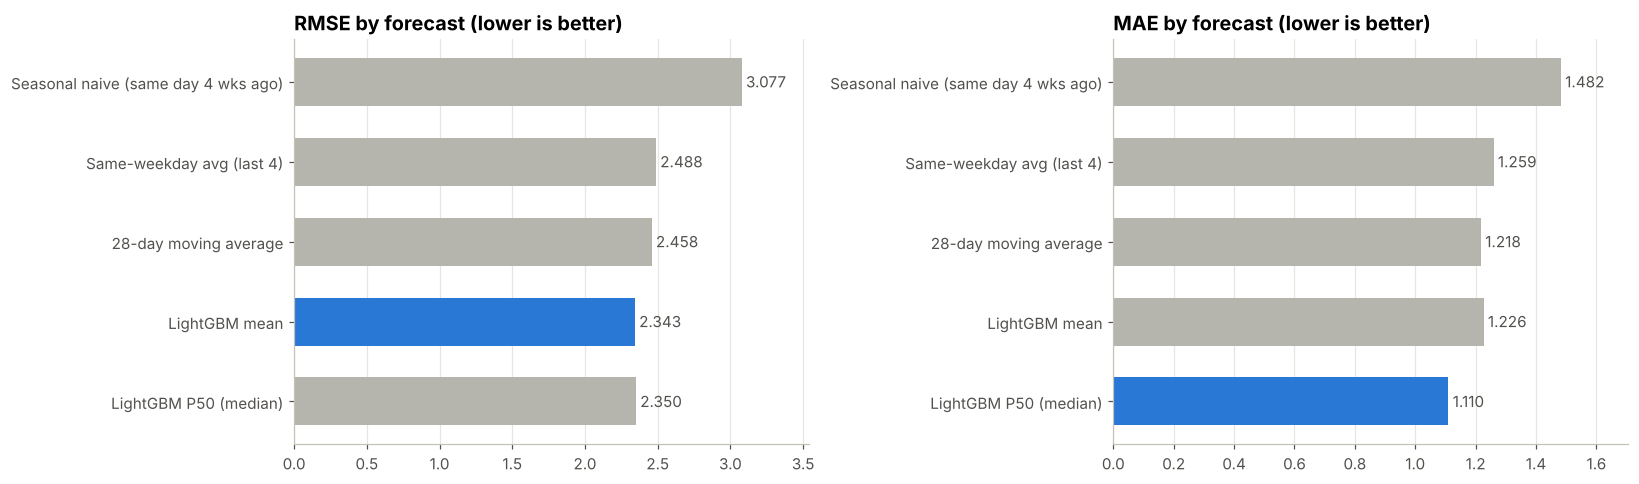

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = list(names.values())
for ax, metric, hl in [(axes[0], 'RMSE', 'LightGBM mean'), (axes[1], 'MAE', 'LightGBM P50 (median)')]:
    vals = scores.loc[order, metric]
    colors = [BLUE if n == hl else GRAY for n in order]
    ax.barh(order[::-1], vals[::-1], color=colors[::-1], height=0.6)
    for y, v in enumerate(vals[::-1]):
        ax.text(v, y, f' {v:.3f}', va='center', color=INK, fontsize=10)
    ax.set_title(f'{metric} by forecast (lower is better)')
    ax.set_xlim(0, vals.max() * 1.15)
    ax.grid(axis='y', visible=False)
fig.tight_layout()
save_fig(fig, '03_01_accuracy_vs_baselines')
plt.show()

## Step 4 — Is the uncertainty honest? (P50 / P90 calibration)

A P90 forecast is useful only if actual sales really stay **at or below it on ~90% of days**. We check that (*coverage*) and the **pinball loss** — the standard score for quantile forecasts (lower is better) — against the naive empirical quantiles of the last 28 days.

In [6]:
def pinball(y, q, alpha):
    d = y - q
    return np.maximum(alpha * d, (alpha - 1) * d).mean()

calib = pd.DataFrame({
    'Coverage (target)': ['50%', '50%', '90%', '90%'],
    'Coverage (actual)': [(ev['sales'] <= ev[c]).mean() for c in ['naive_p50', 'p50', 'naive_p90', 'p90']],
    'Pinball loss': [pinball(ev['sales'], ev[c], a) for c, a in
                     [('naive_p50', .5), ('p50', .5), ('naive_p90', .9), ('p90', .9)]],
}, index=['Naive P50 (last 28 days)', 'LightGBM P50', 'Naive P90 (last 28 days)', 'LightGBM P90'])
print(calib.to_string(formatters={'Coverage (actual)': '{:.1%}'.format, 'Pinball loss': '{:.4f}'.format}))
print(f"\nP90 pinball loss vs naive: {calib.loc['LightGBM P90','Pinball loss'] / calib.loc['Naive P90 (last 28 days)','Pinball loss'] - 1:+.1%}")
print("Note: with whole-unit sales, 'sales <= P50' includes ties at 0, so P50 coverage sits above 50%.")

                         Coverage (target) Coverage (actual) Pinball loss
Naive P50 (last 28 days)               50%             66.2%       0.5728
LightGBM P50                           50%             61.7%       0.5550
Naive P90 (last 28 days)               90%             89.4%       0.4032
LightGBM P90                           90%             90.5%       0.3569

P90 pinball loss vs naive: -11.5%
Note: with whole-unit sales, 'sales <= P50' includes ties at 0, so P50 coverage sits above 50%.


## Step 5 — What the forecasts look like

Saved: reports/figures/03_02_total_actual_vs_forecast.png


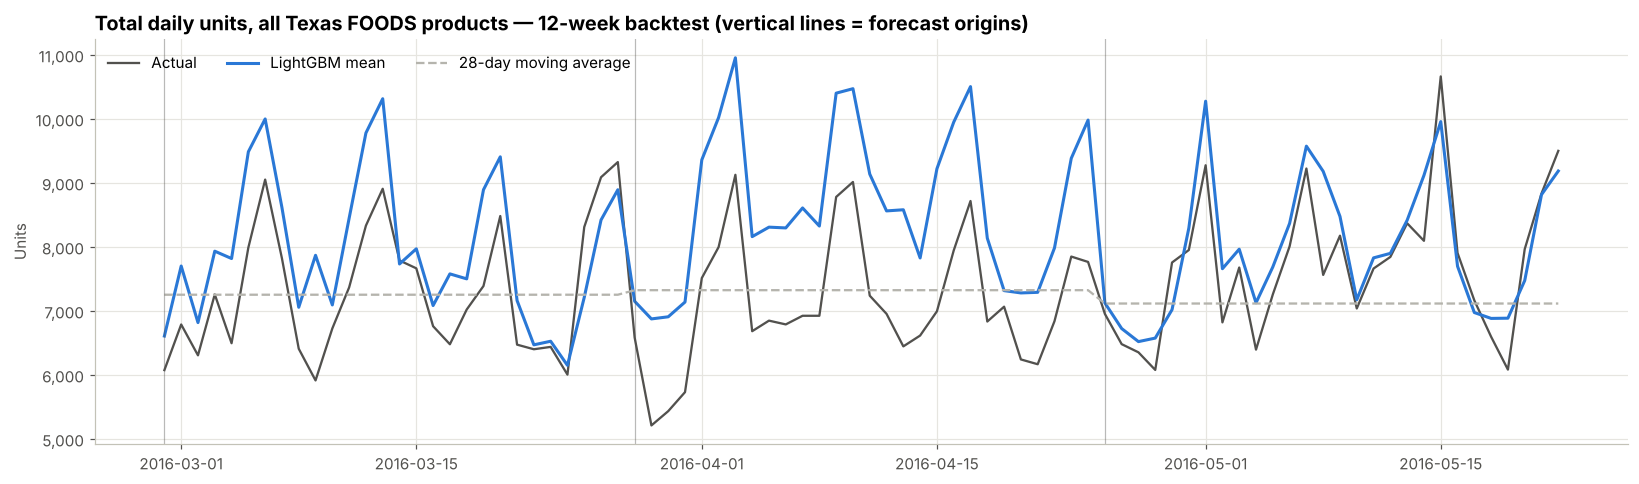

Saved: reports/figures/03_03_product_forecast_band.png


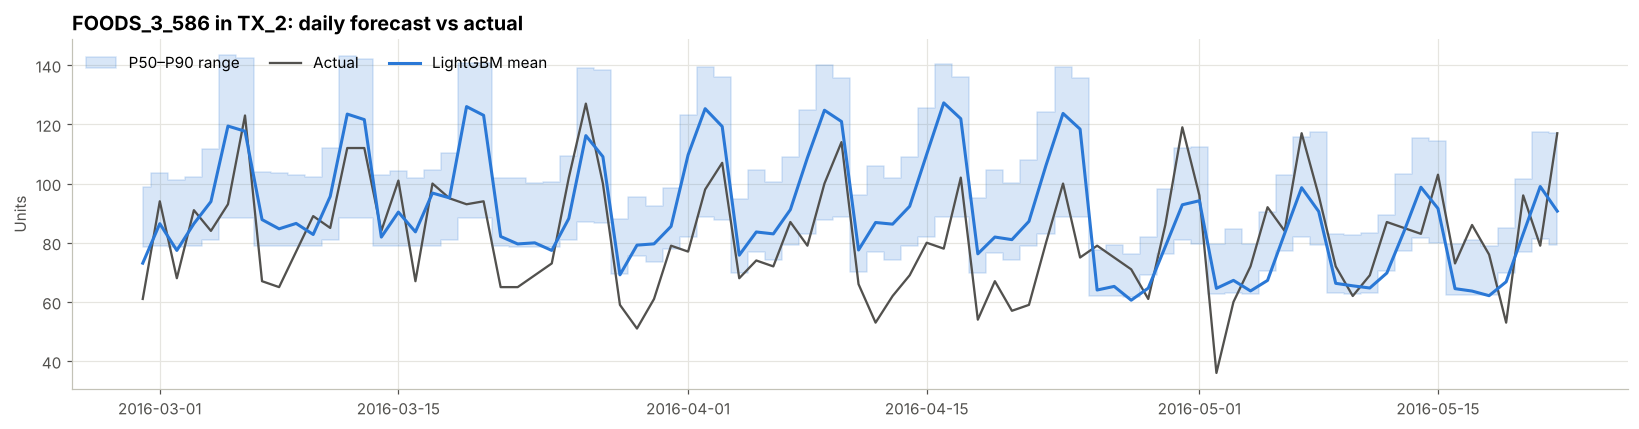

Saved: reports/figures/03_04_feature_importance.png


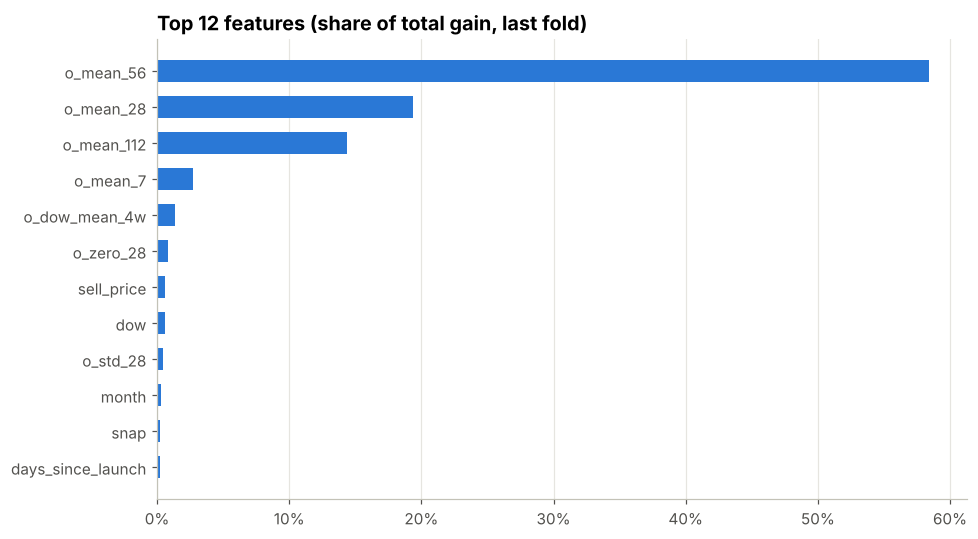

In [7]:
# All products together: actual vs forecast per day (sums of means are valid; sums of quantiles are not)
tot = fc.groupby('date')[['sales', 'mean', 'o_mean_28']].sum()
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(tot.index, tot['sales'], color=INK, linewidth=1.5, label='Actual')
ax.plot(tot.index, tot['mean'], color=BLUE, label='LightGBM mean')
ax.plot(tot.index, tot['o_mean_28'], color=GRAY, linestyle='--', linewidth=1.5, label='28-day moving average')
for T in ORIGINS:
    ax.axvline(T, color=INK, linewidth=0.8, alpha=0.4)
ax.set_title('Total daily units, all Texas FOODS products — 12-week backtest (vertical lines = forecast origins)')
ax.set_ylabel('Units'); ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
ax.legend(loc='upper left', ncol=3)
fig.tight_layout(); save_fig(fig, '03_02_total_actual_vs_forecast'); plt.show()

# One busy product with its P50–P90 band
item, store = 'FOODS_3_586', 'TX_2'
one = fc[(fc['item_id'] == item) & (fc['store_id'] == store)].set_index('date')
fig, ax = plt.subplots(figsize=(15, 4))
ax.fill_between(one.index, one['p50'], one['p90'], color=BLUE, alpha=0.18, step='mid', label='P50–P90 range')
ax.plot(one.index, one['sales'], color=INK, linewidth=1.5, label='Actual')
ax.plot(one.index, one['mean'], color=BLUE, label='LightGBM mean')
ax.set_title(f'{item} in {store}: daily forecast vs actual'); ax.set_ylabel('Units')
ax.legend(loc='upper left', ncol=3)
fig.tight_layout(); save_fig(fig, '03_03_product_forecast_band'); plt.show()

# What drives the model
imp = (importance / importance.sum()).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_title('Top 12 features (share of total gain, last fold)')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0)); ax.grid(axis='y', visible=False)
fig.tight_layout(); save_fig(fig, '03_04_feature_importance'); plt.show()

## Step 6 — Save forecasts for Notebook 04

In [8]:
OUT = os.path.join(PROCESSED_DIR, 'forecasts_backtest.parquet')
fc.to_parquet(OUT, index=False)
print(f"Saved {len(fc):,} rows → {os.path.relpath(OUT, PROJECT_DIR)} ({os.path.getsize(OUT) / 1e6:.1f} MB)")
print(fc.columns.tolist())

Saved 362,124 rows → data/processed/forecasts_backtest.parquet (8.8 MB)
['item_id', 'store_id', 'dept_id', 'date', 'sales', 'unavailable', 'sell_price', 'horizon', 'snaive_28', 'o_dow_mean_4w', 'o_mean_28', 'o_std_28', 'fold', 'mean', 'p50', 'p90', 'naive_p50', 'naive_p90']


## Summary — Notebook 03

**Forecast accuracy (12 backtest weeks, likely-unavailable days excluded)**

| | Seasonal naive | 28-day moving avg | **LightGBM** | Gain vs moving avg |
|---|---|---|---|---|
| RMSE (mean forecast) | 3.077 | 2.458 | **2.343** | **−4.7%** (−23.9% vs seasonal naive) |
| MAE (P50 forecast) | 1.482 | 1.218 | **1.110** | **−8.8%** (−25.1% vs seasonal naive) |

- **Beats the strongest baseline (28-day moving average) in all 3 folds** on both metrics.
- **Uncertainty is honest:** the P90 forecast covers **90.5%** of days (target 90%) and cuts pinball loss **11.5%** vs. the naive P90 from the last 28 days.
- **Known bias, explained:** the mean forecast runs **+5.5% above actual sales**. It is trained only on days the product was on the shelf, so it forecasts *demand when available*, while observed sales still contain short stockouts the deliberately conservative flag (Notebook 02) didn't catch. The total-units chart shows this offset. Notebook 04 compares policies **at equal inventory**, so a uniform level offset can't manufacture the inventory gain.
- **What drives it:** recent sales levels (56 / 28 / 112-day averages) carry most of the signal; short-term trend, day of week, price and SNAP refine it.

→ **Next:** Notebook 04 turns these forecasts into ordering decisions.